# Infinite-width Gaussian-RBF kernel solution of \(u''=\sin(\omega x)\)

This notebook solves

\[
u''(x)=\sin(\omega x),\qquad x\in[-2\pi,2\pi],
\]

with two conditions imposed at \(x=0\),

\[
u(0)=0,\qquad u'(0)=-\frac1\omega.
\]

The exact solution is

\[
u_{\rm exact}(x)=-\frac{1}{\omega^2}\sin(\omega x).
\]

Unlike the finite-center Gaussian expansion in the supplied MATLAB code, this
notebook uses the **analytic infinite-width Gaussian-RBF kernel** obtained by
averaging Gaussian features over a continuum of centers. The value and derivative
boundary constraints are imposed first through a null-space projection; the ODE is
then solved in that admissible coefficient space.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import svd
from time import perf_counter


In [2]:
import numpy as np
from scipy.special import erf

def radical_inverse(n, b=2):
    n = np.asarray(n, dtype=int).copy()
    r = np.zeros_like(n, dtype=float)
    f = 1.0 / b
    while np.any(n > 0):
        r += f * (n % b)
        n //= b
        f /= b
    return r

def rbf1d_uniform_derivs_full(x, y, sigma, ca, cb):
    """
    Exact expectation over c ~ Uniform[ca,cb] of products of fixed-width
    Gaussian RBFs and all derivatives needed up to 2+2 order.

    Returns:
      K      = k
      K1     = d/dx k
      K2     = d/dy k
      K11    = d2/dx2 k
      K22    = d2/dy2 k
      K12    = d2/dxdy k
      K112   = d3/dx2dy k
      K122   = d3/dxdy2 k
      K1122  = d4/dx2dy2 k
    """
    x = np.asarray(x, dtype=float).reshape(-1, 1)
    y = np.asarray(y, dtype=float).reshape(1, -1)

    m = 0.5*(x+y)
    d = x-y
    A = 0.5*d
    za = ca-m
    zb = cb-m

    Ed = np.exp(-(d**2)/(4*sigma**2))
    ea = np.exp(-(za/sigma)**2)
    eb = np.exp(-(zb/sigma)**2)
    E = erf(zb/sigma)-erf(za/sigma)

    J0 = 0.5*sigma*np.sqrt(np.pi)*E
    J1 = 0.5*sigma**2*(ea-eb)
    J2 = 0.25*sigma**3*np.sqrt(np.pi)*E - 0.5*sigma**2*(zb*eb-za*ea)
    J3 = -0.5*sigma**2*(zb**2*eb-za**2*ea) + sigma**2*J1
    J4 = -0.5*sigma**2*(zb**3*eb-za**3*ea) + 1.5*sigma**2*J2

    C = 1/(cb-ca)
    F = C*Ed

    Iq = A*J0-J1
    Ir = -A*J0-J1
    Iq2 = A**2*J0-2*A*J1+J2
    Ir2 = A**2*J0+2*A*J1+J2
    Iqr = J2-A**2*J0
    Iq2r = -A**3*J0+A**2*J1+A*J2-J3
    Iqr2 = A**3*J0+A**2*J1-A*J2-J3
    Iq2r2 = A**4*J0-2*A**2*J2+J4

    K = F*J0
    K1 = -F*Iq/sigma**2
    K2 = -F*Ir/sigma**2
    K11 = F*(Iq2/sigma**4-J0/sigma**2)
    K22 = F*(Ir2/sigma**4-J0/sigma**2)
    K12 = F*Iqr/sigma**4
    K112 = F*(-Iq2r/sigma**6+Ir/sigma**4)
    K122 = F*(-Iqr2/sigma**6+Iq/sigma**4)
    K1122 = F*(Iq2r2/sigma**8-(Iq2+Ir2)/sigma**6+J0/sigma**4)

    return K,K1,K2,K11,K22,K12,K112,K122,K1122

def compute_kernel_norm(cfg):
    xr = 0.5*(cfg["xL"]+cfg["xR"])
    K = rbf1d_uniform_derivs_full(
        [xr],[xr],cfg["sigma"],cfg["c_a"],cfg["c_b"]
    )[0]
    return float(K[0,0])

def kernel_1d(cfg, x1, x2, type1, type2):
    K,K1,K2,K11,K22,K12,K112,K122,K1122 = rbf1d_uniform_derivs_full(
        x1,x2,cfg["sigma"],cfg["c_a"],cfg["c_b"]
    )

    table = {
        ("val","val"): K,
        ("dx","val"): K1,
        ("val","dx"): K2,
        ("dx","dx"): K12,
        ("dxx","val"): K11,
        ("val","dxx"): K22,
        ("dxx","dx"): K112,
        ("dx","dxx"): K122,
        ("dxx","dxx"): K1122,
    }
    try:
        return table[(type1,type2)] / cfg["norm_const"]
    except KeyError:
        raise ValueError(f"Unsupported functional pair: {type1}, {type2}")

def predict_u(cfg, alpha, xP, bc_x, xq, batch=1000):
    """
    Representation:
      u(q) = sum alpha_P[j] d2/dy2 k(q,xP_j)
           + alpha_D k(q,bc_x)
           + alpha_N d/dy k(q,bc_x)
    """
    xq = np.asarray(xq, dtype=float).ravel()
    xP = np.asarray(xP, dtype=float).ravel()
    Np = xP.size
    out = np.zeros_like(xq)

    for i1 in range(0, xq.size, batch):
        ids = slice(i1, min(i1+batch, xq.size))
        q = xq[ids]
        KP = kernel_1d(cfg,q,xP,"val","dxx")
        KD = kernel_1d(cfg,q,[bc_x],"val","val")
        KN = kernel_1d(cfg,q,[bc_x],"val","dx")
        out[ids] = np.hstack([KP,KD,KN]) @ alpha
    return out

def predict_ux(cfg, alpha, xP, bc_x, xq, batch=1000):
    xq = np.asarray(xq, dtype=float).ravel()
    xP = np.asarray(xP, dtype=float).ravel()
    out = np.zeros_like(xq)
    for i1 in range(0, xq.size, batch):
        ids = slice(i1, min(i1+batch, xq.size))
        q = xq[ids]
        KP = kernel_1d(cfg,q,xP,"dx","dxx")
        KD = kernel_1d(cfg,q,[bc_x],"dx","val")
        KN = kernel_1d(cfg,q,[bc_x],"dx","dx")
        out[ids] = np.hstack([KP,KD,KN]) @ alpha
    return out

def predict_uxx(cfg, alpha, xP, bc_x, xq, batch=1000):
    xq = np.asarray(xq, dtype=float).ravel()
    xP = np.asarray(xP, dtype=float).ravel()
    out = np.zeros_like(xq)
    for i1 in range(0, xq.size, batch):
        ids = slice(i1, min(i1+batch, xq.size))
        q = xq[ids]
        KP = kernel_1d(cfg,q,xP,"dxx","dxx")
        KD = kernel_1d(cfg,q,[bc_x],"dxx","val")
        KN = kernel_1d(cfg,q,[bc_x],"dxx","dx")
        out[ids] = np.hstack([KP,KD,KN]) @ alpha
    return out

In [3]:
# ------------------------------ problem ---------------------------------
omega = 15.0
xL = -2*np.pi
xR =  2*np.pi

bc_x  = 0.0
bc_u  = 0.0
bc_du = -1.0/omega

def rhs_fun(x):
    return np.sin(omega*np.asarray(x,float))

def uexact(x):
    return -(1.0/omega**2)*np.sin(omega*np.asarray(x,float))

def duexact(x):
    return -(1.0/omega)*np.cos(omega*np.asarray(x,float))

# ------------------------ kernel / collocation --------------------------
Np = 801

# Deterministic quasi-uniform PDE points.
# A shifted base-2 radical-inverse sequence avoids coincident endpoint structure.
h = radical_inverse(np.arange(1,Np+1),2)
xP = np.sort(xL + (xR-xL)*h)

# Kernel width: small enough to resolve omega=15 oscillations.
sigma = 0.10

# Uniform continuum of RBF centers on a padded physical interval.
pad = 0.75
c_a = xL - pad
c_b = xR + pad

ridge_rel = 1e-11

cfg = {
    "xL":xL, "xR":xR,
    "sigma":sigma,
    "c_a":c_a, "c_b":c_b,
}
cfg["norm_const"] = compute_kernel_norm(cfg)

print("INFINITE-RBF KERNEL ODE SOLVER")
print(f"omega                       = {omega:g}")
print(f"domain                      = [{xL:.6f}, {xR:.6f}]")
print(f"PDE collocation points      = {Np}")
print(f"kernel sigma                = {sigma:.4f}")
print(f"center-support interval     = [{c_a:.3f}, {c_b:.3f}]")

INFINITE-RBF KERNEL ODE SOLVER
omega                       = 15
domain                      = [-6.283185, 6.283185]
PDE collocation points      = 801
kernel sigma                = 0.1000
center-support interval     = [-7.033, 7.033]


In [4]:
# --------------------- dual kernel system -------------------------------
_t_solve_total0 = perf_counter()
_t0 = perf_counter()
#
# Coefficient vector:
#   alpha = [alpha_P ; alpha_D ; alpha_N]
#
# Basis representers:
#   alpha_P : second-derivative functional on the second kernel argument
#   alpha_D : value functional at x=0
#   alpha_N : first-derivative functional at x=0

# ODE rows: u''(xP) = sin(omega*xP)
K_PP = kernel_1d(cfg,xP,xP,"dxx","dxx")
K_PD = kernel_1d(cfg,xP,[bc_x],"dxx","val")
K_PN = kernel_1d(cfg,xP,[bc_x],"dxx","dx")
Amat = np.hstack([K_PP,K_PD,K_PN])
rhsP = rhs_fun(xP)

# Boundary row 1: u(0)=bc_u
B_D_P = kernel_1d(cfg,[bc_x],xP,"val","dxx")
B_D_D = kernel_1d(cfg,[bc_x],[bc_x],"val","val")
B_D_N = kernel_1d(cfg,[bc_x],[bc_x],"val","dx")
row_D = np.hstack([B_D_P,B_D_D,B_D_N])

# Boundary row 2: u'(0)=bc_du
B_N_P = kernel_1d(cfg,[bc_x],xP,"dx","dxx")
B_N_D = kernel_1d(cfg,[bc_x],[bc_x],"dx","val")
B_N_N = kernel_1d(cfg,[bc_x],[bc_x],"dx","dx")
row_N = np.hstack([B_N_P,B_N_D,B_N_N])

Bmat = np.vstack([row_D,row_N])
bBC = np.array([bc_u,bc_du])

t_kernel_assembly = perf_counter() - _t0

print("PDE matrix shape             =",Amat.shape)
print("Boundary matrix shape        =",Bmat.shape)
print(f"kernel/operator assembly time = {t_kernel_assembly:.6f} s")


PDE matrix shape             = (801, 803)
Boundary matrix shape        = (2, 803)
kernel/operator assembly time = 0.213009 s


In [5]:
# --------------------- null-space boundary projection -------------------
_t0 = perf_counter()
# Minimum-norm particular solution satisfying both BCs.
alpha_p = np.linalg.pinv(Bmat,rcond=1e-13) @ bBC

# Full SVD to get complete right null space of Bmat.
Ub,sB,Vhb = svd(Bmat,full_matrices=True)

tolB = max(Bmat.shape)*np.finfo(float).eps*np.max(sB)
rankB = int(np.sum(sB > tolB))
Vb = Vhb.T
Q = Vb[:,rankB:]

t_nullspace = perf_counter() - _t0

print(f"Boundary rank                = {rankB}")
print(f"Null-space dimension         = {Q.shape[1]}")
print(f"||B Q||_F                    = {np.linalg.norm(Bmat@Q):.3e}")
print(f"particular BC max error      = {np.max(np.abs(Bmat@alpha_p-bBC)):.3e}")
print(f"constraint/null-space time   = {t_nullspace:.6f} s")


Boundary rank                = 2
Null-space dimension         = 801
||B Q||_F                    = 6.126e-13
particular BC max error      = 1.388e-17
constraint/null-space time   = 0.007699 s


In [6]:
# ------------------------ reduced ODE solve -----------------------------
_t0 = perf_counter()
Ared = Amat @ Q
bred = rhsP - Amat @ alpha_p

Ua,sa,Vha = svd(Ared,full_matrices=False)
if sa.size == 0 or sa[0] <= 0:
    raise RuntimeError("Reduced kernel system is singular.")

lam = ridge_rel * sa[0]**2
filt = sa/(sa**2 + lam)
eta = Vha.T @ (filt*(Ua.T @ bred))
alpha = alpha_p + Q @ eta

t_reduced_solve = perf_counter() - _t0
t_total_solve = perf_counter() - _t_solve_total0

print(f"Reduced system               = {Ared.shape[0]} x {Ared.shape[1]}")
print(f"ridge lambda                 = {lam:.3e}")
print(f"reduced SVD/solve time       = {t_reduced_solve:.6f} s")
print(f"total assembly+solve time    = {t_total_solve:.6f} s")


Reduced system               = 801 x 801
ridge lambda                 = 1.497e-01
reduced SVD/solve time       = 0.299432 s
total assembly+solve time    = 0.530984 s


In [7]:
# ----------------------------- diagnostics ------------------------------
_t0 = perf_counter()
x_test = np.linspace(xL,xR,5001)
u_pred = predict_u(cfg,alpha,xP,bc_x,x_test)
ux_pred = predict_ux(cfg,alpha,xP,bc_x,x_test)
uxx_pred = predict_uxx(cfg,alpha,xP,bc_x,x_test)

t_prediction = perf_counter() - _t0

u_ex = uexact(x_test)
ux_ex = duexact(x_test)
res = uxx_pred - rhs_fun(x_test)
err = u_pred - u_ex

rmse = np.sqrt(np.mean(err**2))
max_error = np.max(np.abs(err))
res_rms = np.sqrt(np.mean(res**2))
res_max = np.max(np.abs(res))

bc_u_fit = float(predict_u(cfg,alpha,xP,bc_x,[bc_x])[0])
bc_du_fit = float(predict_ux(cfg,alpha,xP,bc_x,[bc_x])[0])

print(f"solution RMSE                = {rmse:.6e}")
print(f"solution max error           = {max_error:.6e}")
print(f"residual RMS                 = {res_rms:.6e}")
print(f"residual max                 = {res_max:.6e}")
print(f"u(0)                         = {bc_u_fit:.12e}")
print(f"u'(0)                        = {bc_du_fit:.12e}")
print(f"target u'(0)                 = {bc_du:.12e}")
print(f"dense prediction time        = {t_prediction:.6f} s")


solution RMSE                = 9.964863e-05
solution max error           = 2.240409e-04
residual RMS                 = 2.034864e-04
residual max                 = 7.694872e-03
u(0)                         = -6.445581915426e-17
u'(0)                        = -6.666666666667e-02
target u'(0)                 = -6.666666666667e-02
dense prediction time        = 2.525443 s


In [8]:
# ----------------------------- archive ----------------------------------
np.savez_compressed(
    "INF_RBF_ODE_SINE_RESULTS.npz",
    omega=omega,xL=xL,xR=xR,bc_x=bc_x,bc_u=bc_u,bc_du=bc_du,
    Np=Np,xP=xP,sigma=sigma,pad=pad,c_a=c_a,c_b=c_b,ridge_rel=ridge_rel,
    alpha=alpha,alpha_p=alpha_p,Q=Q,rankB=rankB,tolB=tolB,lam=lam,
    x_test=x_test,u_pred=u_pred,ux_pred=ux_pred,uxx_pred=uxx_pred,
    u_exact=u_ex,ux_exact=ux_ex,residual=res,error=err,
    rmse=rmse,max_error=max_error,res_rms=res_rms,res_max=res_max,
    bc_u_fit=bc_u_fit,bc_du_fit=bc_du_fit,
    t_kernel_assembly=t_kernel_assembly,t_nullspace=t_nullspace,t_reduced_solve=t_reduced_solve,t_total_solve=t_total_solve,t_prediction=t_prediction
)
print("Saved INF_RBF_ODE_SINE_RESULTS.npz")

Saved INF_RBF_ODE_SINE_RESULTS.npz


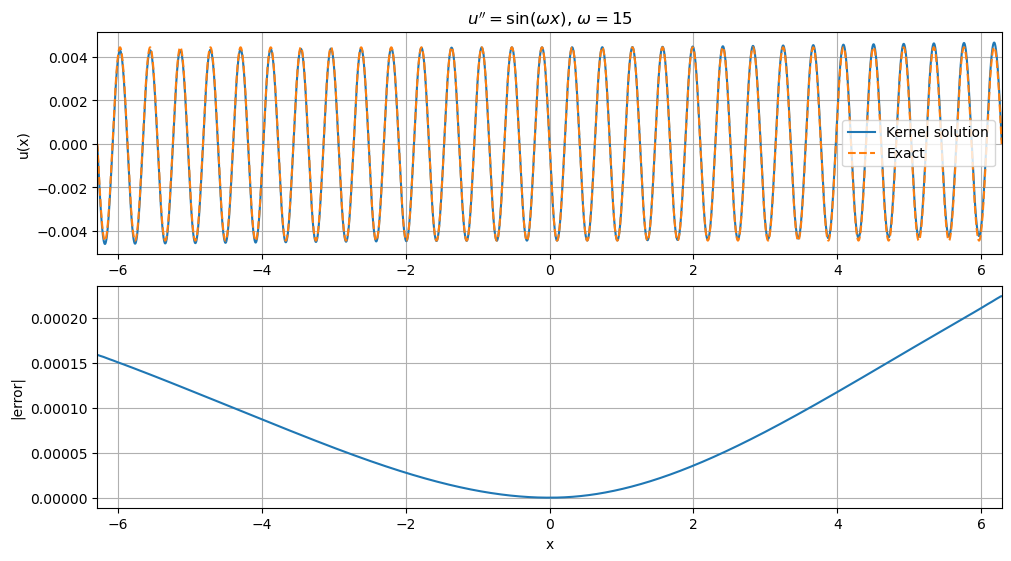

In [9]:
# -------------------------- quick validation plots ----------------------
fig,axes = plt.subplots(2,1,figsize=(10,5.5),constrained_layout=True)

axes[0].plot(x_test,u_pred,"-",label="Kernel solution")
axes[0].plot(x_test,u_ex,"--",label="Exact")
axes[0].set_xlim(xL,xR)
axes[0].set_ylabel("u(x)")
axes[0].grid(True)
axes[0].legend()
axes[0].set_title(rf"$u''=\sin(\omega x)$, $\omega={omega:g}$")

axes[1].plot(x_test,np.abs(err))
axes[1].set_xlim(xL,xR)
axes[1].set_xlabel("x")
axes[1].set_ylabel("|error|")
axes[1].grid(True)

plt.show()